# 07 · Actor-crítico, GAE y PPO
**Entornos:** MiniDespacho (mediano) · **Tiempo de ejecución:** ≤ 8 min en CPU · **Criterio de la lección:** PPO le gana a `GreedyDespacho`: diferencia pareada con LB > 0 (n = 1000 semillas de evaluación).

## 1. La idea en una frase
PPO combina un **actor** (la política) y un **crítico** (el valor), estima la ventaja de cada acción con **GAE** y actualiza la política con una pérdida **recortada** que impide pasos demasiado grandes.

**En el sistema de Luca:** es exactamente el algoritmo de entrenamiento (PPO + GAE con recompensa +1/0/−1); el Transformer es el actor-crítico.
**En un problema de negocio:** el crítico estima cuánto costo futuro queda; la ventaja dice si una asignación fue mejor o peor de lo esperado.

## 2. La intuición y la fórmula
**Ventaja generalizada (GAE).** Con el error TD $\delta_t = r_t + \gamma V(s_{t+1}) - V(s_t)$:

$$\hat A_t = \delta_t + \gamma\lambda\,\hat A_{t+1}.$$

$\lambda=0$ da el error TD de un paso (sesgo, poca varianza); $\lambda=1$ da retorno de Monte Carlo menos $V$ (sin sesgo, mucha varianza). En medio se elige el compromiso.

**Pérdida recortada.** Con la razón $\rho_t = \pi_\theta(a_t|s_t)/\pi_{\text{old}}(a_t|s_t)$:

$$\mathcal{L}^{\text{clip}} = -\,\mathbb{E}\bigl[\min\bigl(\rho_t \hat A_t,\; \text{clip}(\rho_t,\,1-\varepsilon,\,1+\varepsilon)\,\hat A_t\bigr)\bigr]$$

más la pérdida del crítico $(V(s_t)-\hat R_t)^2$ y un bono de entropía. El recorte permite reutilizar varias épocas del mismo lote sin que la política se aleje demasiado.

In [1]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt
from rlf.core import EVAL_SEED_BASE, VecEnv, seed_everything
from rlf.eval.stats import mean_ci, paired_diff_ci, passes_lower
from rlf.eval.arena import evaluate_policy
from rlf.envs.despacho import DespachoEnv
from rlf.agents.baselines import RandomPolicy, GreedyDespacho
from rlf.agents.policy import ActorCriticPolicy
from rlf.agents.reinforce import Reinforce
from rlf.agents.ppo import PPO, PPOConfig, compute_gae
from rlf.nets.mlp import MLPActorCritic
TRAIN_SEED = int(os.environ.get("RLF_TRAIN_SEED", "0"))
seed_everything(TRAIN_SEED)
make_env = lambda: DespachoEnv.from_size("mediano")
SPEC = make_env().spec

## 3. El núcleo: GAE y la pérdida recortada
Escritos inline. Dos celdas los comprueban: GAE contra `rlf.agents.ppo.compute_gae` y la pérdida recortada con números a mano.

In [2]:
def gae_inline(rewards, values, dones, last_value, gamma, lam):
    """rewards, values, dones: [T, B]. Recorre el rollout hacia atrás acumulando Â_t = δ_t + γλ Â_{t+1}."""
    T = len(rewards)
    adv = np.zeros_like(rewards, dtype=float)
    running, next_value = np.zeros(rewards.shape[1]), np.asarray(last_value, float)
    for t in reversed(range(T)):
        not_done = 1.0 - dones[t]                                   # al terminar el episodio no hay futuro
        delta = rewards[t] + gamma * next_value * not_done - values[t]
        running = delta + gamma * lam * not_done * running
        adv[t] = running
        next_value = values[t]
    return adv, adv + values

def clipped_policy_loss(logp_new, logp_old, adv, clip_eps=0.2):
    """−E[min(ρ Â, clip(ρ, 1−ε, 1+ε) Â)]."""
    ratio = torch.exp(logp_new - logp_old)
    return -torch.min(ratio * adv, torch.clamp(ratio, 1 - clip_eps, 1 + clip_eps) * adv).mean()

rng = np.random.default_rng(TRAIN_SEED)
r, v, last = rng.normal(size=(20, 3)), rng.normal(size=(20, 3)), rng.normal(size=3)
d = rng.random((20, 3)) < 0.1
a1, ret1 = gae_inline(r, v, d, last, 0.97, 0.9)
a2, ret2 = compute_gae(r, v, d, last, 0.97, 0.9)
assert np.allclose(a1, a2) and np.allclose(ret1, ret2)
# ρ = 1,5 con Â > 0 se recorta a 1,2; con Â < 0 no se recorta (el mínimo elige el término sin recortar)
lp_new, lp_old = torch.log(torch.tensor([1.5, 1.5])), torch.zeros(2)
assert abs(float(clipped_policy_loss(lp_new, lp_old, torch.tensor([1.0, 1.0]))) + 1.2) < 1e-6
assert abs(float(clipped_policy_loss(lp_new, lp_old, torch.tensor([-1.0, -1.0]))) - 1.5) < 1e-6
print("GAE inline == rlf; pérdida recortada verificada a mano")

GAE inline == rlf; pérdida recortada verificada a mano


## 4. Entrenar y graficar la curva de aprendizaje
1 000 000 de pasos de entorno (64 entornos en paralelo, rollouts de 64 pasos, 10 épocas por lote), γ = 0,97, λ = 0,9. Evaluamos la política **greedy** (argmax) cada 250 000 pasos con n = 1000 semillas.

aleatorio -118.2   GreedyDespacho -77.5


  250000 pasos: retorno  -76.70   PPO − greedy =  0.77  IC95 [-1.63,  3.17]   entropía 0.164


  500000 pasos: retorno  -73.46   PPO − greedy =  4.00  IC95 [ 1.60,  6.41]   entropía 0.198


  750000 pasos: retorno  -72.40   PPO − greedy =  5.07  IC95 [ 2.56,  7.57]   entropía 0.185


 1000000 pasos: retorno  -72.33   PPO − greedy =  5.14  IC95 [ 2.70,  7.58]   entropía 0.173


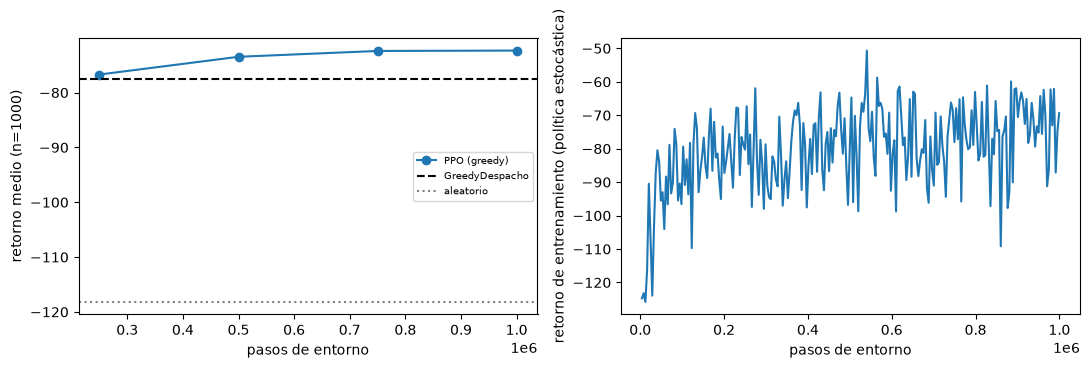

In [3]:
N = 1000
rand_ret = evaluate_policy(make_env, RandomPolicy(TRAIN_SEED), N)
greedy_ret = evaluate_policy(make_env, GreedyDespacho(), N)
print(f"aleatorio {rand_ret.mean():.1f}   GreedyDespacho {greedy_ret.mean():.1f}")

def ppo_config(**kw):
    base = dict(gamma=0.97, lam=0.9, lr=1e-3, n_steps=64, epochs=10, minibatches=8, clip_eps=0.2, reward_scale=1 / 68)
    return PPOConfig(**{**base, **kw})

def new_ppo(cfg, seed=TRAIN_SEED):
    torch.manual_seed(seed)
    return PPO(MLPActorCritic(SPEC, hidden=(128, 128)), cfg, seed=seed)

def eval_ppo(ppo, n=N):
    return evaluate_policy(make_env, ActorCriticPolicy(ppo.net, greedy=True), n)

ppo = new_ppo(ppo_config())
vec = VecEnv(make_env, 64, seed=TRAIN_SEED)
curve = []
for chunk in range(4):
    ppo.train(vec, 250_000)
    ret = eval_ppo(ppo)
    curve.append((250_000 * (chunk + 1), ret.mean(), paired_diff_ci(ret, greedy_ret)))
    print(f"{curve[-1][0]:8d} pasos: retorno {ret.mean():7.2f}   PPO − greedy = {curve[-1][2].mean:5.2f}  IC95 [{curve[-1][2].lo:5.2f}, {curve[-1][2].hi:5.2f}]   entropía {ppo.history[-1]['entropy']:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
xs = [c[0] for c in curve]
ax[0].plot(xs, [c[1] for c in curve], marker="o", label="PPO (greedy)")
ax[0].axhline(greedy_ret.mean(), color="k", ls="--", label="GreedyDespacho"); ax[0].axhline(rand_ret.mean(), color="gray", ls=":", label="aleatorio")
ax[0].set_xlabel("pasos de entorno"); ax[0].set_ylabel("retorno medio (n=1000)"); ax[0].legend(fontsize=7)
ax[1].plot([h["steps"] for h in ppo.history], [h["mean_return"] for h in ppo.history]); ax[1].set_xlabel("pasos de entorno"); ax[1].set_ylabel("retorno de entrenamiento (política estocástica)")
plt.tight_layout(); plt.show()
final_ret = eval_ppo(ppo)

## 5. Experimentos "predice antes de correr"
Cada experimento entrena **60 000 pasos** (64 entornos) con la configuración de arriba salvo lo que se cambia, y evalúa la política greedy con n = 1000 semillas.

In [4]:
def short_run(**kw):
    p = new_ppo(ppo_config(**kw))
    p.train(VecEnv(make_env, 64, seed=TRAIN_SEED), 60_000)
    return eval_ppo(p)
BASE = short_run()
print(f"línea base (λ=0,9, ε=0,2, 10 épocas): {BASE.mean():.2f}   (aleatorio {rand_ret.mean():.1f})")

línea base (λ=0,9, ε=0,2, 10 épocas): -87.47   (aleatorio -118.2)


### Experimento 1 · λ = 0 vs 0,95 vs 1
**Predice:** ¿qué pasa con λ = 0 (solo el error TD de un paso)? ¿Y con λ = 1 (retorno completo)?

In [5]:
LAM = {lam: short_run(lam=lam) for lam in (0.0, 0.95, 1.0)}
print({k: round(float(v.mean()), 2) for k, v in LAM.items()}, "  (λ=0,9:", round(float(BASE.mean()), 2), ")")
assert LAM[0.0].mean() < min(LAM[0.95].mean(), LAM[1.0].mean()) - 20

{0.0: -180.26, 0.95: -94.89, 1.0: -91.7}   (λ=0,9: -87.47 )


<details><summary>Respuesta esperada</summary>

**λ = 0 es un desastre** (≈ −180, peor que el aleatorio de ≈ −118): con un crítico todavía malo, el error TD de un paso propaga casi nada de la recompensa real y los sesgos del crítico dominan. Con λ = 0,95 y λ = 1
aprende (≈ −95 y ≈ −92), y λ = 0,9 fue algo mejor en esta corrida (≈ −87). El compromiso sesgo-varianza de GAE importa: por eso no se usa ni un extremo ni otro.
</details>

### Experimento 2 · Con y sin recorte (`clip_eps` ∈ {0,1, 0,2, ∞})
**Predice:** ¿el recorte ayuda o estorba? ¿Qué pasa si se desactiva (ε = ∞)?

In [6]:
CLIP = {c: short_run(clip_eps=c) for c in (0.1, 0.2, float("inf"))}
print({k: round(float(v.mean()), 2) for k, v in CLIP.items()})
assert all(v.mean() > rand_ret.mean() + 10 for v in CLIP.values())                 # los tres aprenden algo
assert CLIP[0.2].mean() > CLIP[float("inf")].mean()

{0.1: -90.6, 0.2: -87.47, inf: -93.13}


<details><summary>Respuesta esperada</summary>

Los tres aprenden, pero con recorte 0,2 (≈ −87) se aprende mejor que sin recorte (≈ −93); con 0,1 (≈ −91) el recorte es demasiado conservador. Sin recorte, diez épocas sobre el mismo lote permiten pasos
que alejan la política de los datos con que se calcularon las ventajas. Con una sola corrida de 60 000 pasos las diferencias pequeñas (≈ 3 unidades) no son concluyentes; la del extremo sin recorte es la más clara.
</details>

### Experimento 3 · 1 vs 4 vs 10 épocas por lote
**Predice:** con el mismo número de pasos de entorno, ¿más épocas por lote aprenden más rápido?

In [7]:
EP = {e: short_run(epochs=e) for e in (1, 4)}
EP[10] = BASE
print({k: round(float(v.mean()), 2) for k, v in EP.items()})
assert EP[10].mean() > EP[1].mean() + 5 and EP[10].mean() > EP[4].mean() + 5

{1: -99.45, 4: -98.63, 10: -87.47}


<details><summary>Respuesta esperada</summary>

Más épocas aprenden **más rápido por paso de entorno** (10 épocas ≈ −87; 1 y 4 épocas ≈ −99): cada lote de experiencia, que es lo caro, se exprime más. El recorte es lo que hace seguro reutilizarlo.
A cambio, cada iteración cuesta más cómputo de red.
</details>

### Experimento 4 · PPO vs REINFORCE con el mismo número de pasos
**Predice:** con ≈ 60 000 pasos de entorno cada uno, ¿quién aprende más?

In [8]:
def reinforce_run(seed=TRAIN_SEED):
    torch.manual_seed(seed)
    ag = Reinforce(MLPActorCritic(SPEC, hidden=(128, 128)), "value", gamma=0.97, lr=1e-3, entropy_coef=0.01,
                   reward_scale=1 / 68, normalize_adv=True, seed=seed)
    ag.train(VecEnv(make_env, 16, seed=seed), 24, 64)            # ≈ 60 000 pasos: 24 actualizaciones de 64 episodios
    steps = sum(h["n_steps"] for h in ag.history)
    return evaluate_policy(make_env, ActorCriticPolicy(ag.net, greedy=True), N), steps
REINF, reinf_steps = reinforce_run()
d = paired_diff_ci(BASE, REINF)
print(f"REINFORCE ({reinf_steps} pasos): {REINF.mean():.2f}   PPO (60 000 pasos): {BASE.mean():.2f}   PPO − REINFORCE = {d.mean:.2f} [{d.lo:.2f}, {d.hi:.2f}]")
assert d.lo > 0

REINFORCE (67936 pasos): -97.36   PPO (60 000 pasos): -87.47   PPO − REINFORCE = 9.89 [7.01, 12.77]


<details><summary>Respuesta esperada</summary>

PPO gana con claridad (≈ −87 frente a ≈ −97): reutiliza cada lote 10 veces, tiene un crítico entrenado en paralelo que reduce la varianza (GAE) y no tira los datos tras un solo gradiente.
En la lección 6, REINFORCE necesitó ≈ 51 000 episodios (millones de pasos) para llegar a un nivel más modesto.
</details>

## 6. Criterio de la lección
n = 1000 semillas de evaluación, política greedy (argmax) del PPO entrenado 1 000 000 de pasos.

In [9]:
diff = paired_diff_ci(final_ret, greedy_ret)
ok_a = passes_lower(diff, 1e-12)
print(f"{'afirmación':70s} resultado")
print(f"{'(a) PPO − GreedyDespacho = %.2f  IC95 [%.2f, %.2f], LB > 0' % (diff.mean, diff.lo, diff.hi):70s} {ok_a}")
print(f"    (PPO {final_ret.mean():.2f}, greedy {greedy_ret.mean():.2f}, aleatorio {rand_ret.mean():.2f})")
assert ok_a

afirmación                                                             resultado
(a) PPO − GreedyDespacho = 5.14  IC95 [2.70, 7.58], LB > 0             True
    (PPO -72.33, greedy -77.47, aleatorio -118.18)


## 7. Resumen y puente a la lección siguiente
- PPO = actor + crítico + GAE + pérdida recortada; aquí superó a la heurística greedy con un MLP que puntúa los ids de acción.
- λ, el recorte y las épocas por lote importan: se midieron, no se supusieron.
- Pero ese MLP tiene una limitación: su cabeza de acción está atada a los **ids** de este tamaño de entorno. **Lección 8:** enmascarado y *pointer attention* sobre las features de las opciones, que transfiere a otros tamaños.